In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data analysis and visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_ImadolLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,relativehumidity,48.915001,%,2025-11-06 12:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,12:45:00
1,6121047,Imadol(SC-27)- GD Labs,relativehumidity,36.130417,%,2025-11-06 13:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,13:45:00
2,6121047,Imadol(SC-27)- GD Labs,relativehumidity,34.523250,%,2025-11-06 14:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,14:45:00
3,6121047,Imadol(SC-27)- GD Labs,relativehumidity,37.322875,%,2025-11-06 15:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,15:45:00
4,6121047,Imadol(SC-27)- GD Labs,relativehumidity,40.794792,%,2025-11-06 16:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,16:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6121047,Imadol(SC-27)- GD Labs,relativehumidity,44.000000,%,2026-02-26 17:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,17:45:00
996,6121047,Imadol(SC-27)- GD Labs,relativehumidity,44.000000,%,2026-02-26 18:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,18:45:00
997,6121047,Imadol(SC-27)- GD Labs,relativehumidity,44.000000,%,2026-02-26 19:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,19:45:00
998,6121047,Imadol(SC-27)- GD Labs,relativehumidity,44.000000,%,2026-02-26 20:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,20:45:00


In [3]:
df365['date'].unique()

<ArrowStringArray>
['2025-11-06', '2025-11-07', '2025-11-08', '2025-11-09', '2025-11-10',
 '2025-11-11', '2025-11-12', '2025-11-13', '2025-11-14', '2025-11-15',
 '2025-11-16', '2025-11-17', '2025-11-18', '2025-11-19', '2025-11-20',
 '2025-11-21', '2025-11-22', '2025-11-23', '2025-11-24', '2025-11-25',
 '2025-11-26', '2026-02-03', '2026-02-04', '2026-02-05', '2026-02-06',
 '2026-02-07', '2026-02-08', '2026-02-09', '2026-02-10', '2026-02-11',
 '2026-02-12', '2026-02-13', '2026-02-14', '2026-02-15', '2026-02-16',
 '2026-02-17', '2026-02-18', '2026-02-19', '2026-02-20', '2026-02-21',
 '2026-02-22', '2026-02-23', '2026-02-24', '2026-02-25', '2026-02-26']
Length: 45, dtype: str

In [4]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df365.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [5]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2025-11-06,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,44.36,12
1,2025-11-07,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,44.60,24
2,2025-11-08,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,42.21,24
3,2025-11-09,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,41.74,14
4,2025-11-10,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,39.82,18
5,2025-11-11,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,42.62,24
6,2025-11-12,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,45.89,18
7,2025-11-13,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,42.05,23
8,2025-11-14,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,46.46,15
9,2025-11-15,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,42.96,24


/tmp/ipykernel_37881/2403254589.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


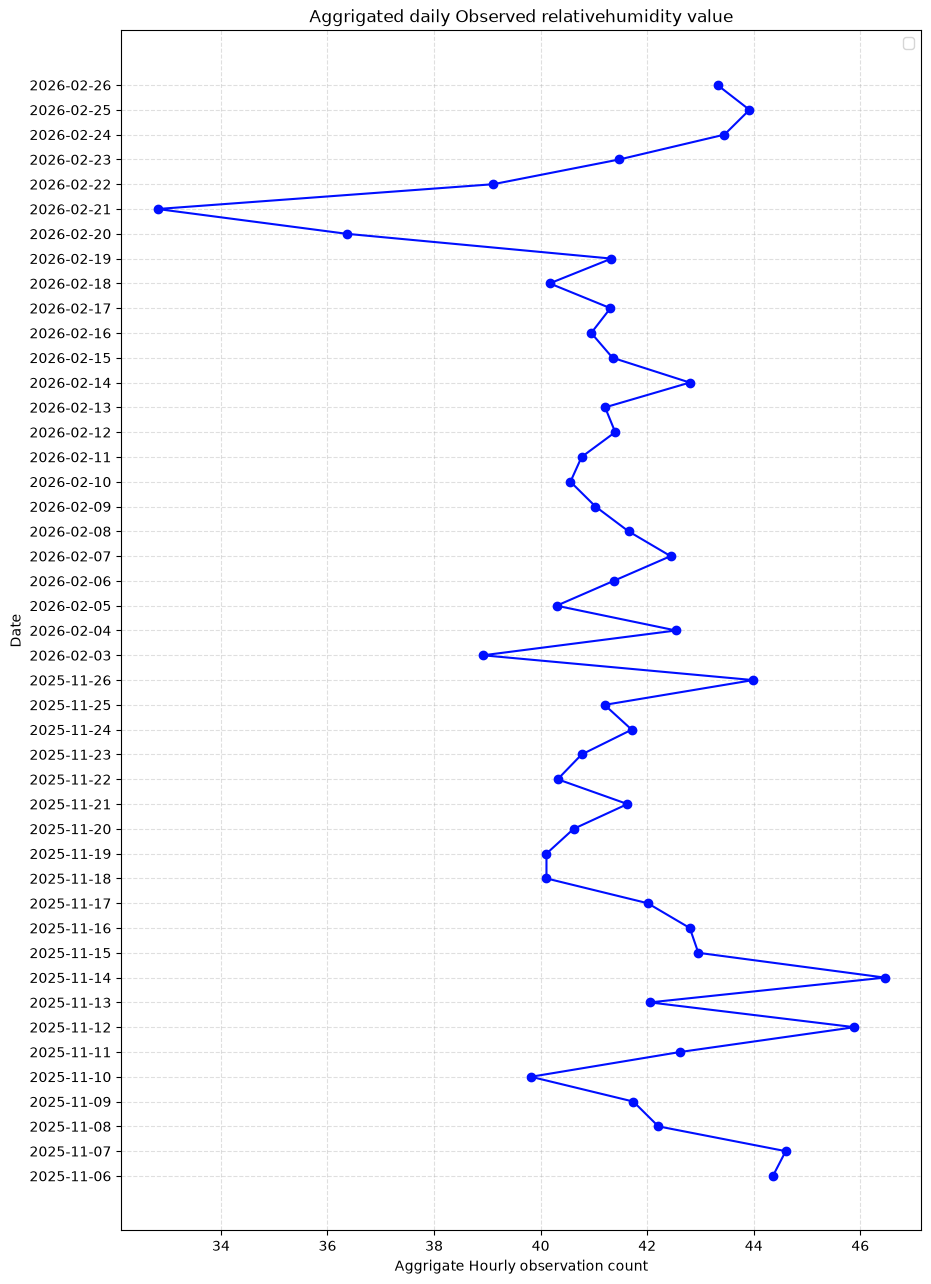

In [6]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 37 days

In [7]:
df30 = pd.read_csv('cleaned_ImadolLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,relativehumidity,57.0,%,2026-09-05 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,relativehumidity,57.0,%,2026-09-05 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,relativehumidity,53.0,%,2026-09-05 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,relativehumidity,49.0,%,2026-09-05 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,relativehumidity,47.0,%,2026-09-05 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
879,6121047,Imadol(SC-27)- GD Labs,relativehumidity,51.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
880,6121047,Imadol(SC-27)- GD Labs,relativehumidity,51.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
881,6121047,Imadol(SC-27)- GD Labs,relativehumidity,52.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
882,6121047,Imadol(SC-27)- GD Labs,relativehumidity,53.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [8]:
df30['date'].unique

<bound method Series.unique of 0      2026-09-05
1      2026-09-05
2      2026-09-05
3      2026-09-05
4      2026-09-05
          ...    
879    2026-10-12
880    2026-10-12
881    2026-10-12
882    2026-10-12
883    2026-10-12
Name: date, Length: 884, dtype: str>

In [9]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [10]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-05,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,55.17,18
1,2026-09-06,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,54.96,24
2,2026-09-07,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,53.42,24
3,2026-09-08,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,50.21,24
4,2026-09-09,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,52.54,24
5,2026-09-10,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,51.71,24
6,2026-09-11,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,50.12,24
7,2026-09-12,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,50.88,24
8,2026-09-13,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,50.08,24
9,2026-09-14,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,49.67,24


/tmp/ipykernel_37881/1124759186.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


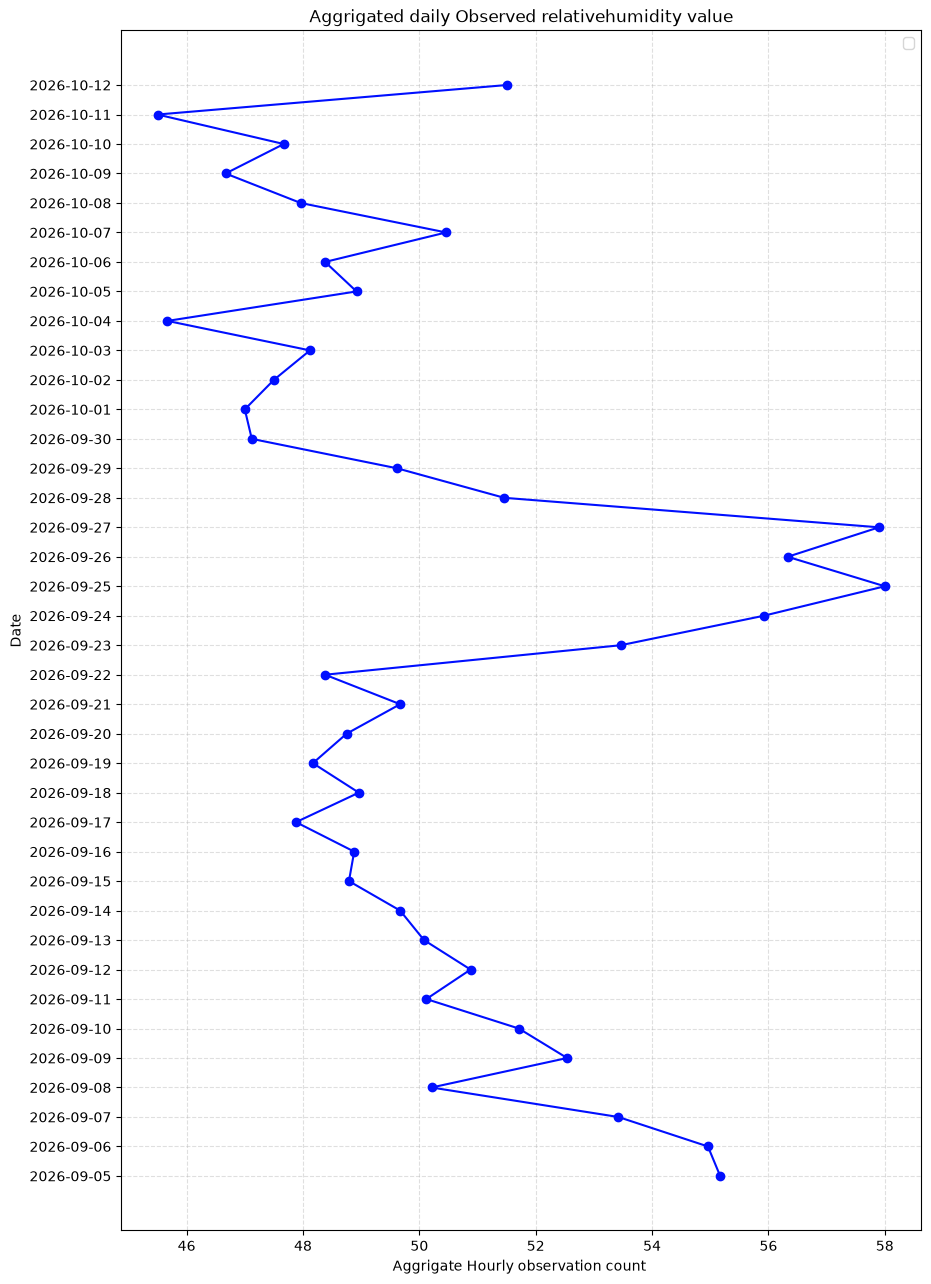

In [11]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [12]:
df7 = pd.read_csv('cleaned_ImadolLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,relativehumidity,52.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,relativehumidity,51.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,relativehumidity,48.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,relativehumidity,45.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,relativehumidity,43.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6121047,Imadol(SC-27)- GD Labs,relativehumidity,51.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,6121047,Imadol(SC-27)- GD Labs,relativehumidity,51.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,6121047,Imadol(SC-27)- GD Labs,relativehumidity,52.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,6121047,Imadol(SC-27)- GD Labs,relativehumidity,53.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [13]:
df7['date'].unique()

<ArrowStringArray>
['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09',
 '2026-10-10', '2026-10-11', '2026-10-12']
Length: 8, dtype: str

In [14]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df7.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [15]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-10-05,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,48.17,18
1,2026-10-06,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,48.38,24
2,2026-10-07,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,50.46,24
3,2026-10-08,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,47.96,24
4,2026-10-09,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,46.67,24
5,2026-10-10,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,47.67,24
6,2026-10-11,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,45.50,24
7,2026-10-12,6121047,Imadol(SC-27)- GD Labs,relativehumidity,%,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,51.50,6


/tmp/ipykernel_37881/3434928225.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


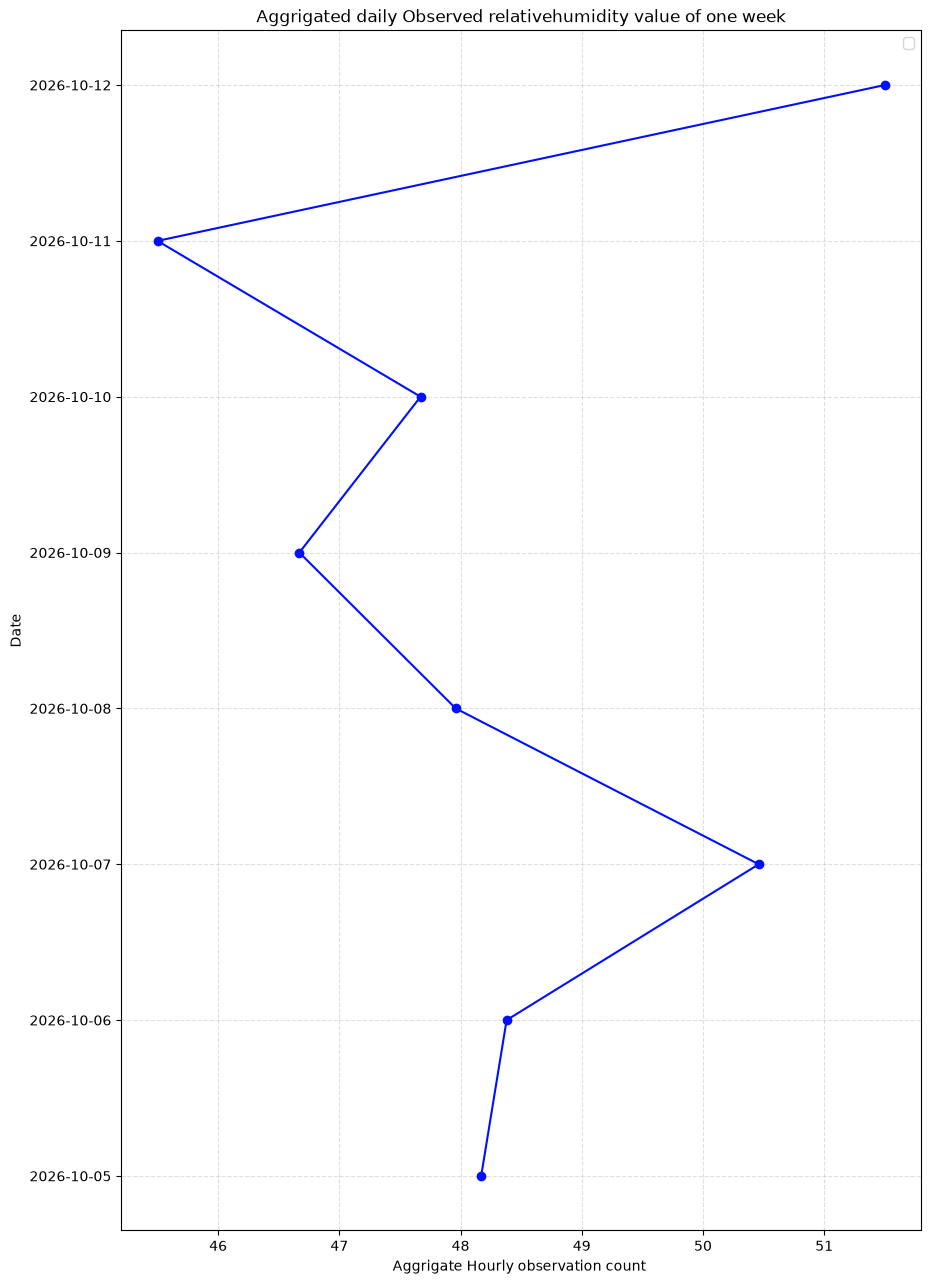

In [16]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [17]:
df24 = pd.read_csv('cleaned_ImadolLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,relativehumidity,53.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,relativehumidity,53.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,relativehumidity,49.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,relativehumidity,45.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,relativehumidity,40.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6121047,Imadol(SC-27)- GD Labs,relativehumidity,36.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6121047,Imadol(SC-27)- GD Labs,relativehumidity,34.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6121047,Imadol(SC-27)- GD Labs,relativehumidity,35.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6121047,Imadol(SC-27)- GD Labs,relativehumidity,35.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6121047,Imadol(SC-27)- GD Labs,relativehumidity,35.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


In [18]:
df24['time'].unique()

<ArrowStringArray>
['06:45:00', '07:45:00', '08:45:00', '09:45:00', '10:45:00', '11:45:00',
 '12:45:00', '13:45:00', '14:45:00', '15:45:00', '16:45:00', '17:45:00',
 '18:45:00', '19:45:00', '20:45:00', '21:45:00', '22:45:00', '23:45:00',
 '00:45:00', '01:45:00', '02:45:00', '03:45:00', '04:45:00', '05:45:00']
Length: 24, dtype: str

In [19]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_37881/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


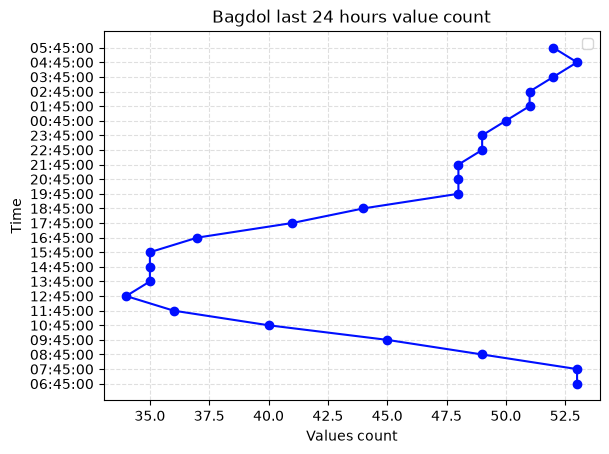

In [20]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()